# 03c · Bootstrap variants for the topic intervals

Notebook 03 builds each topic's 95% interval with a **cluster bootstrap over source channels**. Two
alternatives suggested after the mid-term (D23):

| Variant | What a resample does |
|---|---|
| **global** (notebook 03) | draws as many source channels as there are, from all of them together |
| **by community** | draws within each source community; each community keeps its number of sources |
| **by topic** | draws within each topic; each topic keeps its number of sources |

Topics are channel-level (interim), so every source belongs to exactly one topic. Same populations,
B = 1,000 and seed 42 as notebook 03. Compared on interval width and on the verdicts. Edges `src -> dest`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, plots, crossing

plots.use_style()
OUT = cfg.RESULTS / "03c"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
B, SEED = 1000, cfg.SEED

con = data.connect()
channels = data.channel_table(con).set_index("channel_id")
community = pd.read_parquet(cfg.DERIVED / "communities.parquet").set_index("channel_id").community
fw = pd.read_parquet(data.build_en_text_windows(con))
topics = sorted(channels.ch_topic.dropna().unique())
tcode = {t: i for i, t in enumerate(topics)}
fw = fw.assign(topic=fw.src_id.map(channels.ch_topic).map(tcode),
               src_consp=fw.src_id.map(channels.conspiracy), dest_consp=fw.dest_id.map(channels.conspiracy),
               cross=fw.src_id.map(community).to_numpy() != fw.dest_id.map(community).to_numpy())
STRATA = {"global": None, "by community": community, "by topic": channels.ch_topic.dropna().map(tcode)}

def rows_for(pop, event):
    keep = pop & (fw.n_text > 0)
    d = fw[keep]
    return pd.DataFrame({"topic": d.topic.to_numpy(), "source": d.src_id.to_numpy(),
                         "n": d.n_text.to_numpy(), "x": d.n_text.to_numpy() * event[keep].to_numpy()})

everyone = pd.Series(True, index=fw.index)
measures = {"RQ1 crossing communities": (everyone, fw.cross),
            "RQ2 conspiracy → non-conspiracy": (fw.src_consp, ~fw.dest_consp),
            "RQ2 reverse non-consp. → conspiracy": (~fw.src_consp, fw.dest_consp)}

## 1 · Run the three bootstraps

The global one must reproduce notebook 03 exactly.

In [2]:
saved = {"RQ1 crossing communities": "03_rq1_topics.csv", "RQ2 conspiracy → non-conspiracy": "03_rq2_topics.csv",
         "RQ2 reverse non-consp. → conspiracy": "03_rq2_reverse_topics.csv"}
res = {}
for name, (pop, ev) in measures.items():
    rows = rows_for(pop, ev)
    res[name] = {k: crossing.topic_table(rows, topics, B, SEED, strata=s) for k, s in STRATA.items()}
    ref = pd.read_csv(cfg.RESULTS / "03" / saved[name])
    assert np.allclose(res[name]["global"].excess_low_pp, ref.excess_low_pp) and (res[name]["global"].verdict == ref.verdict).all()
print("global bootstrap reproduces notebook 03 for all three measures")

global bootstrap reproduces notebook 03 for all three measures


In [3]:
rows_out = []
for name, tabs in res.items():
    g = tabs["global"]
    for i, t in enumerate(topics):
        r = {"measure": name, "topic": t, "sources": int(g.sources[i]), "rate": g.rate[i]}
        for k, tab in tabs.items():
            r[f"interval {k} (pp)"] = f"[{tab.excess_low_pp[i]:+.1f}, {tab.excess_high_pp[i]:+.1f}]"
            r[f"verdict {k}"] = tab.verdict[i]
            if k != "global":
                r[f"width ratio {k}"] = (tab.excess_high_pp[i] - tab.excess_low_pp[i]) / (g.excess_high_pp[i] - g.excess_low_pp[i])
        rows_out.append(r)
cmp = pd.DataFrame(rows_out)
cmp.to_csv(OUT / "03c_comparison.csv", index=False)
summ = pd.DataFrame({k: {name: {"median width ratio vs global": cmp[cmp.measure == name][f"width ratio {k}"].median(),
                                "verdict changes vs global": int((cmp[cmp.measure == name][f"verdict {k}"] != cmp[cmp.measure == name]["verdict global"]).sum())}
                            for name in measures} for k in ["by community", "by topic"]})
print(pd.DataFrame({(k, m): v for k, d in summ.items() for m, v in d.items()}).T.to_string())
changed = cmp[(cmp["verdict by community"] != cmp["verdict global"]) | (cmp["verdict by topic"] != cmp["verdict global"])]
changed[["measure", "topic", "sources", "verdict global", "verdict by community", "verdict by topic"]].style.hide(axis="index")

                                                  median width ratio vs global  verdict changes vs global
by community RQ1 crossing communities                                 0.988624                        1.0
             RQ2 conspiracy → non-conspiracy                          0.969398                        0.0
             RQ2 reverse non-consp. → conspiracy                      0.998264                        0.0
by topic     RQ1 crossing communities                                 0.984031                        0.0
             RQ2 conspiracy → non-conspiracy                          0.985090                        0.0
             RQ2 reverse non-consp. → conspiracy                      1.032237                        0.0


measure,topic,sources,verdict global,verdict by community,verdict by topic
RQ1 crossing communities,Extremists and radicals,888,less,not distinguishable,less


**Figure 1.** Each topic's 95% interval of its excess over the overall rate (percentage points) under the
three bootstraps. Grey labels: fewer than 30 source channels. Channel-level topics (interim); edges
`src -> dest`.

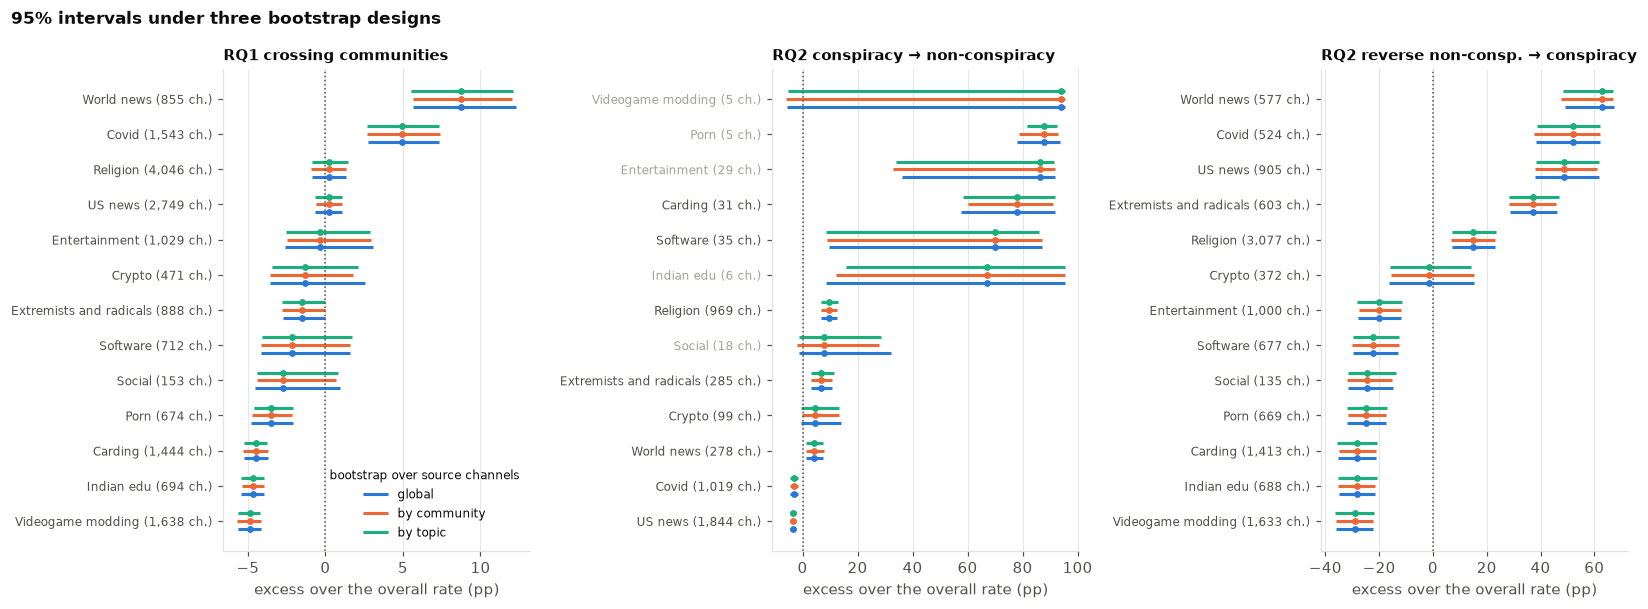

In [4]:
COL = {"global": plots.SERIES[0], "by community": plots.SERIES[1], "by topic": plots.SERIES[2]}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.6))
for ax, (name, tabs) in zip(axes, res.items()):
    g = tabs["global"]
    order = np.argsort(g.excess_pp.to_numpy())
    y = np.arange(len(order))
    for k, dy in zip(tabs, (-0.22, 0.0, 0.22)):
        tab = tabs[k]
        ax.hlines(y + dy, tab.excess_low_pp.to_numpy()[order], tab.excess_high_pp.to_numpy()[order], color=COL[k], lw=2, label=k)
        ax.scatter(tab.excess_pp.to_numpy()[order], y + dy, color=COL[k], s=12, zorder=3)
    ax.axvline(0, color=plots.INK_2, ls=":", lw=1)
    ax.set_yticks(y, [f"{topics[i]} ({g.sources[i]:,} ch.)" for i in order], fontsize=8)
    for lbl, i in zip(ax.get_yticklabels(), order):
        if g.sources[i] < 30: lbl.set_color("#a3a29d")
    ax.set_title(name, loc="left", fontsize=10); ax.grid(axis="y", visible=False)
    ax.set_xlabel("excess over the overall rate (pp)")
axes[0].legend(loc="lower right", fontsize=8, title="bootstrap over source channels", title_fontsize=8)
fig.suptitle("95% intervals under three bootstrap designs", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plots.savefig(fig, "03c_fig1_intervals", OUT)
plt.show()